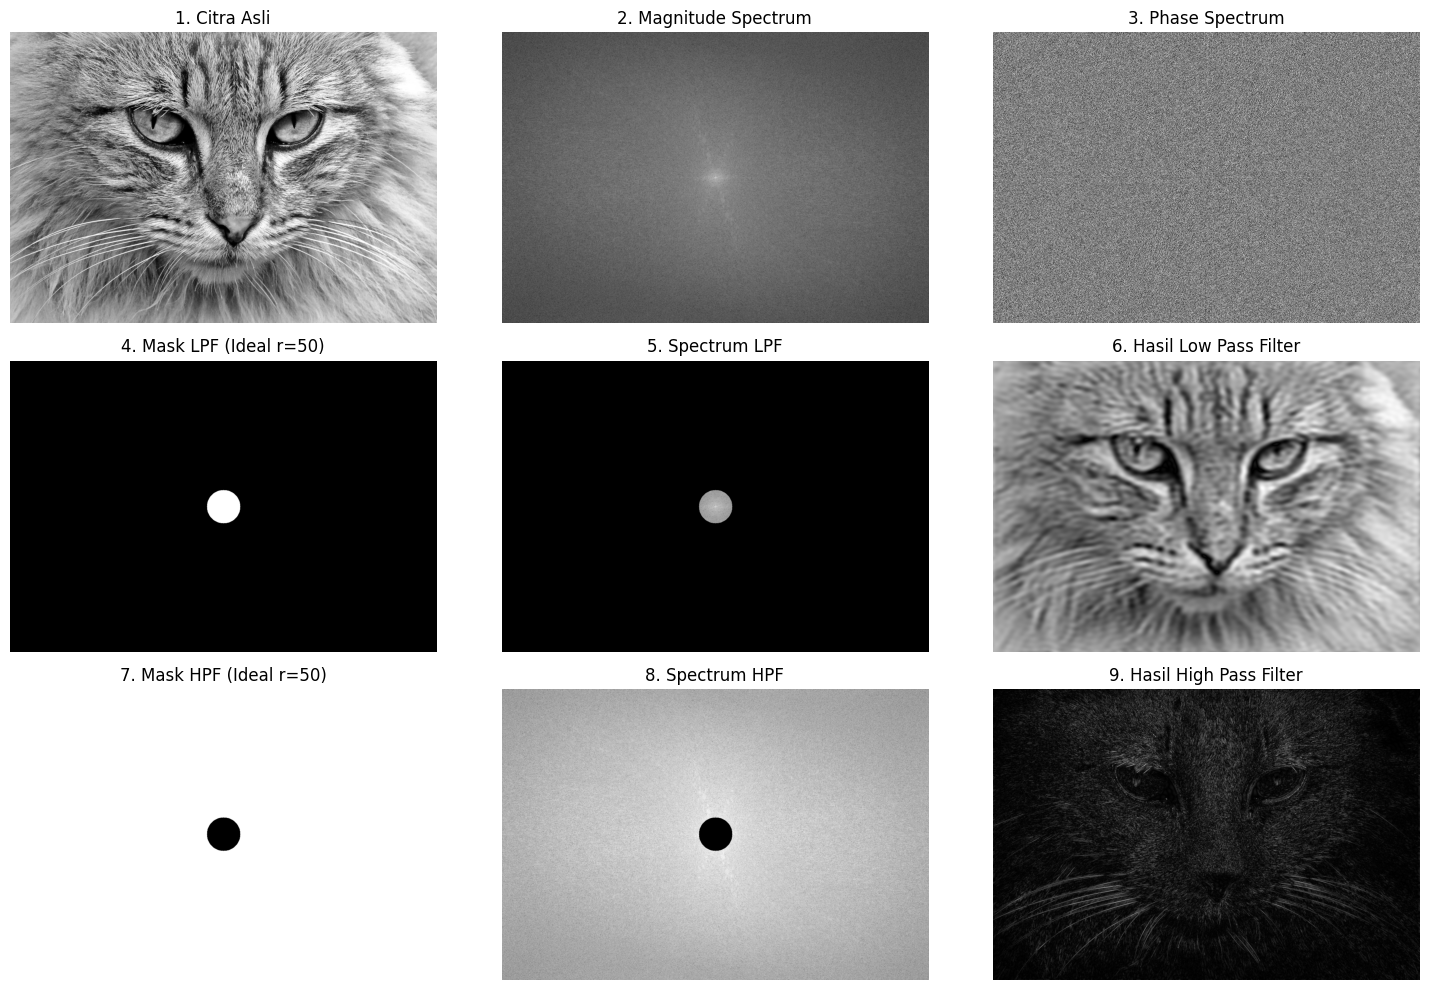

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('img.png', cv2.IMREAD_GRAYSCALE)

f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)
phase_spectrum = np.angle(fshift)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

mask_lpf = np.zeros((rows, cols), np.uint8)
cv2.circle(mask_lpf, (ccol, crow), 50, 1, -1)

fshift_lpf = fshift * mask_lpf
mag_lpf = 20 * np.log(np.abs(fshift_lpf) + 1)
img_lpf = np.abs(np.fft.ifft2(np.fft.ifftshift(fshift_lpf)))

mask_hpf = 1 - mask_lpf
fshift_hpf = fshift * mask_hpf
mag_hpf = 20 * np.log(np.abs(fshift_hpf) + 1)
img_hpf = np.abs(np.fft.ifft2(np.fft.ifftshift(fshift_hpf)))

plt.figure(figsize=(15, 10))

plt.subplot(3, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Citra Asli')
plt.axis('off')

plt.subplot(3, 3, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('2. Magnitude Spectrum')
plt.axis('off')

plt.subplot(3, 3, 3)
plt.imshow(phase_spectrum, cmap='gray')
plt.title('3. Phase Spectrum')
plt.axis('off')

plt.subplot(3, 3, 4)
plt.imshow(mask_lpf, cmap='gray')
plt.title('4. Mask LPF (Ideal r=50)')
plt.axis('off')

plt.subplot(3, 3, 5)
plt.imshow(mag_lpf, cmap='gray')
plt.title('5. Spectrum LPF')
plt.axis('off')

plt.subplot(3, 3, 6)
plt.imshow(img_lpf, cmap='gray')
plt.title('6. Hasil Low Pass Filter')
plt.axis('off')

plt.subplot(3, 3, 7)
plt.imshow(mask_hpf, cmap='gray')
plt.title('7. Mask HPF (Ideal r=50)')
plt.axis('off')

plt.subplot(3, 3, 8)
plt.imshow(mag_hpf, cmap='gray')
plt.title('8. Spectrum HPF')
plt.axis('off')

plt.subplot(3, 3, 9)
plt.imshow(img_hpf, cmap='gray')
plt.title('9. Hasil High Pass Filter')
plt.axis('off')

plt.tight_layout()
plt.show()

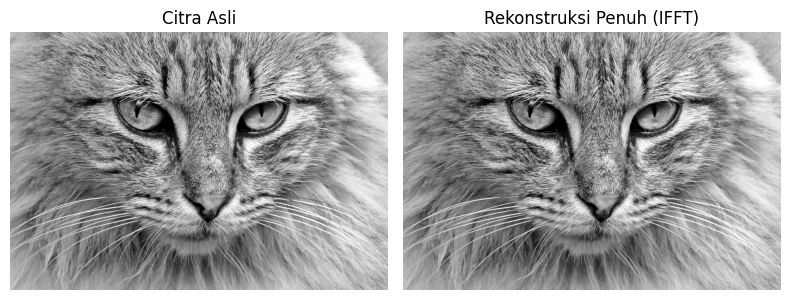

In [4]:
f_ishift = np.fft.ifftshift(fshift)
img_back = np.abs(np.fft.ifft2(f_ishift))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_back, cmap='gray')
plt.title('Rekonstruksi Penuh (IFFT)')
plt.axis('off')

plt.tight_layout()
plt.show()